In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('/Users/ccnlab/Development/dl4rl/')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import seaborn as sns


In [2]:
def prl2_neg_log_likelihood_noisy(actions, rewards, alpha, beta, zeta_sigma):
    # print(alpha, beta)
    num_actions = 2
    q_values = np.array([1 / num_actions] * num_actions)  # equal value first
    q_history = np.zeros((len(actions), 2))
    llh = 0
    for t, (a, r) in enumerate(zip(actions, rewards)):
        q_history[t] = q_values.copy()
        llh += np.log(scipy.special.softmax(beta * q_values)[a])
        # 2. Modify zeta to be sampled from a normal distribution N(1, sigma)
        zeta = np.random.normal(loc=1.0, scale=zeta_sigma)
        
        rpe = r - q_values[a]
        q_values[a] += alpha * rpe * zeta  # update q value
    
    return q_history, -llh

def simulate_two_arm_bandit_noisy(trials, alpha, beta, zeta_sigma, reward_probs):
    """
    Simulates a Q-learning model for a two-arm bandit task (Left and Right).
    
    Parameters:
    trials (int): Total number of trials to simulate.
    alpha (float): Learning rate.
    beta (float): Inverse temperature for the softmax action selection.
    zeta_sigma (float): Standard deviation (sigma) for the unobservable noise process zeta.
    reward_probs (tuple): True reward probabilities for (Left, Right).
    """
    Q = np.array([0.0, 0.0])
    
    actions = np.zeros(trials, dtype=int)
    rewards = np.zeros(trials)
    q_history = np.zeros((trials, 2))
    
    for t in range(trials):
        q_history[t] = Q.copy()
        
        delta_Q = Q[1] - Q[0]
        
        prob_L = 1.0 / (1.0 + np.exp(np.clip(beta * delta_Q, -500, 500)))
        action = 0 if np.random.rand() < prob_L else 1
        actions[t] = action
        
        reward = 1 if np.random.rand() < reward_probs[action] else 0
        rewards[t] = reward
        
        delta_t = reward - Q[action]
        
        # 2. Modify zeta to be sampled from a normal distribution N(1, sigma)
        zeta = np.random.normal(loc=1.0, scale=zeta_sigma)
        
        # Q-value update
        Q[action] = Q[action] + alpha * delta_t * zeta
        
    return actions, rewards, q_history

In [14]:
# Example execution

n_trials = 25
true_probabilities = (0.7, 0.3)
alpha = 0.1
beta = 2.5
zeta_sigma = 0.5

actions, rewards, q_values = simulate_two_arm_bandit_noisy(
    trials=n_trials,
    alpha=alpha,
    beta=beta,
    zeta_sigma=zeta_sigma,  # Passing the standard deviation (sigma) instead of a static zeta
    reward_probs=true_probabilities,
)

res_list = []
for seed in range(10):
    q_values, _ = prl2_neg_log_likelihood_noisy(
        actions, rewards, alpha, beta, zeta_sigma
    )

    res = pd.DataFrame(
        {
            "Q(L)": q_values[:, 0],
            "trial": np.arange(n_trials),
            "action": actions,
            "reward": rewards,
            "Q(R)": q_values[:, 1],
        }
    )
    res["seed"] = seed
    res_list.append(res)

noisy_res = pd.concat(res_list)    

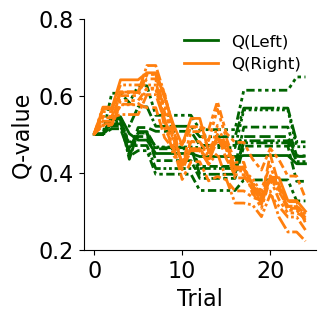

In [16]:

plt.rcParams.update({"font.size": 16})
fig, ax = plt.subplots(figsize=(3, 3))

sns.lineplot(
    data=noisy_res,
    x="trial",
    y="Q(L)",
    ax=ax,
    style="seed",
    legend=False,
    color='darkgreen',
    label="Q(Left)",
    linewidth=2,
)
sns.lineplot(
    data=noisy_res,
    x="trial",
    y="Q(R)",
    ax=ax,
    style="seed",
    color='tab:orange',
    legend=False,
    label="Q(Right)",
    linewidth=2,
)
#ax.set_title("Noisy Q-learning update")
ax.set_xlabel("Trial")
ax.set_ylabel("Q-value")
handles, labels = ax.get_legend_handles_labels()
ax.set_ylim(0.2, 0.8)
# hue entries come first; keep only Q(Left) and Q(Right)
ax.legend([handles[0], handles[10]], [labels[0], labels[10]], frameon=False, fontsize=12)
sns.despine(ax=ax)

fig.savefig(
    f"/Users/ccnlab/Documents/project_dl4rl/Tutorial/sim_noisy_q_learningv2.png",
    dpi=600,
    bbox_inches="tight",
)

In [5]:
def prl2_neg_log_likelihood(actions, rewards, alpha, beta):
    # print(alpha, beta)
    num_actions = 2
    q_values = np.array([1 / num_actions] * num_actions)  # equal value first
    q_history = np.zeros((len(actions), 2))
    llh = 0
    for t, (a, r) in enumerate(zip(actions, rewards)):
        q_history[t] = q_values.copy()
        llh += np.log(scipy.special.softmax(beta * q_values)[a])
        
        rpe = r - q_values[a]
        q_values[a] += alpha * rpe  # update q value
    
    return q_history, -llh

def simulate_two_arm_bandit(trials, alpha, beta, reward_probs):
    """
    Simulates a Q-learning model for a two-arm bandit task (Left and Right).
    
    Parameters:
    trials (int): Total number of trials to simulate.
    alpha (float): Learning rate.
    beta (float): Inverse temperature for the softmax action selection.
    zeta_sigma (float): Standard deviation (sigma) for the unobservable noise process zeta.
    reward_probs (tuple): True reward probabilities for (Left, Right).
    """
    Q = np.array([0.0, 0.0])
    
    actions = np.zeros(trials, dtype=int)
    rewards = np.zeros(trials)
    q_history = np.zeros((trials, 2))
    
    for t in range(trials):
        q_history[t] = Q.copy()
        
        delta_Q = Q[1] - Q[0]
        
        prob_L = 1.0 / (1.0 + np.exp(np.clip(beta * delta_Q, -500, 500)))
        action = 0 if np.random.rand() < prob_L else 1
        actions[t] = action
        
        reward = 1 if np.random.rand() < reward_probs[action] else 0
        rewards[t] = reward
        
        delta_t = reward - Q[action]
    
        # Q-value update
        Q[action] = Q[action] + alpha * delta_t 
        
    return actions, rewards, q_history


n_trials = 25
true_probabilities = (0.7, 0.3) 
alpha = 0.1
beta = 2.5  

actions, rewards, q_values = simulate_two_arm_bandit(
    trials=n_trials, 
    alpha=alpha, 
    beta=beta, 
    reward_probs=true_probabilities
)

res_list = []
for seed in range(10):
    q_values, _ = prl2_neg_log_likelihood(
        actions, rewards, alpha, beta
    )

    res = pd.DataFrame({'Q(L)': q_values[:, 0], 'trial': np.arange(n_trials), 'action': actions, 'reward': rewards, 'Q(R)': q_values[:, 1]})
    res['seed'] = seed
    res_list.append(res)

noiseless_res = pd.concat(res_list)

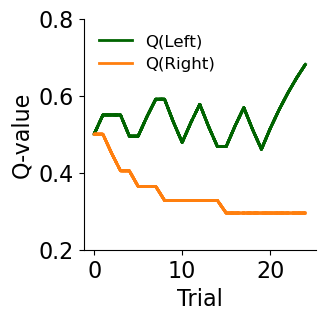

In [10]:
plt.rcParams.update({"font.size": 16})
fig, ax = plt.subplots(figsize=(3, 3))
sns.lineplot(
    data=noiseless_res,
    x="trial",
    y="Q(L)",
    ax=ax,
    style="seed",
    color='darkgreen',
    legend=False,
    label="Q(Left)",
    linewidth=2,
)
sns.lineplot(
    data=noiseless_res,
    x="trial",
    y="Q(R)",
    ax=ax,
    style="seed",
    color='tab:orange',
    legend=False,
    label="Q(Right)",
    linewidth=2,
)
#ax.set_title("Noiseless Q-learning update")
ax.set_xlabel("Trial")
ax.set_ylabel("Q-value")
handles, labels = ax.get_legend_handles_labels()
ax.set_ylim(0.2, 0.8)
# hue entries come first; keep only Q(Left) and Q(Right)
ax.legend([handles[0], handles[10]], [labels[0], labels[10]], frameon=False, fontsize=12)
sns.despine(ax=ax)

fig.savefig(
    f"/Users/ccnlab/Documents/project_dl4rl/Tutorial/sim_noiseless_q_learningv2.png",
    dpi=600,
    bbox_inches="tight",
)